In [51]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Number of records
n_samples = 1000

# Generate dummy columns
loan_id = [f'LP{str(i).zfill(4)}' for i in range(1, n_samples + 1)]
applicant_income = np.random.randint(2000, 15000, size=n_samples)
coapplicant_income = np.random.choice([0, np.random.randint(1000, 8000)], size=n_samples, p=[0.3, 0.7])
loan_amount = np.random.randint(50, 500, size=n_samples) * 1000  # in USD
credit_score = np.random.randint(300, 850, size=n_samples)
property_area = np.random.choice(['Urban', 'Semi-Urban', 'Rural'], size=n_samples)

# New columns requested
age = np.random.randint(18, 70, size=n_samples)
previous_loan_dues = np.random.choice(['Yes', 'No'], size=n_samples, p=[0.2, 0.8])
assets = np.random.randint(5000, 500000, size=n_samples)

# Deterministic but noisy target variable: Loan_Status (Approved 'Y' or Rejected 'N')
# Base decision logic on credit score, income-to-loan ratio, previous dues, and assets
score_factor = (credit_score - 300) / 550.0
income_factor = (applicant_income + coapplicant_income) / (loan_amount / 10.0)
dues_factor = np.where(previous_loan_dues == 'Yes', -2.0, 0.5)
assets_factor = assets / (loan_amount + 1.0)

prob = 1 / (1 + np.exp(-(score_factor * 3 + income_factor * 0.4 + dues_factor + assets_factor * 0.5 - 2)))
loan_status = np.where(np.random.rand(n_samples) < prob, 'Approved', 'Rejected')

# Create DataFrame
df_loans = pd.DataFrame({
    'Loan_ID': loan_id,
    'Applicant_Income': applicant_income,
    'Coapplicant_Income': coapplicant_income,
    'Loan_Amount': loan_amount,
    'Credit_Score': credit_score,
    'Property_Area': property_area,
    'Age': age,
    'Previous_Loan_Dues': previous_loan_dues,
    'Assets': assets,
    'Loan_Status': loan_status
})

# Display summary and the first few rows of the dataset
print(f'Dataset Shape: {df_loans.shape}')
display(df_loans.head())

Dataset Shape: (1000, 10)


,Loan_ID,Applicant_Income,Coapplicant_Income,Loan_Amount,Credit_Score,Property_Area,Age,Previous_Loan_Dues,Assets,Loan_Status
0,LP0001,9270,0,185000,346,Rural,62,No,318732,Approved
1,LP0002,2860,0,402000,753,Rural,55,No,174357,Approved
2,LP0003,7390,0,428000,500,Rural,46,No,131683,Rejected
3,LP0004,7191,0,119000,423,Urban,22,No,261157,Rejected
4,LP0005,13964,6585,474000,300,Urban,26,Yes,210827,Rejected


In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Separate features (X) and target (y)
X = df_loans.drop(columns=['Loan_ID', 'Loan_Status'])
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0})  # Encode target to numeric

# Define columns by type including the new columns
numerical_cols = ['Applicant_Income', 'Coapplicant_Income', 'Loan_Amount', 'Credit_Score', 'Age', 'Assets']
categorical_cols = ['Property_Area', 'Previous_Loan_Dues']

# Create preprocessor
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ])

# Create Logistic Regression pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=42))
])

# Split into training and test sets (20% test size)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Train the model
model_pipeline.fit(X_train, y_train)

# Make predictions
y_pred = model_pipeline.predict(X_test)

# Evaluate model
accuracy = accuracy_score(y_test, y_pred)
print(f'Model Accuracy: {accuracy:.4f}\n')
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=['Rejected', 'Approved']))

Model Accuracy: 0.7600

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.74      0.61      0.67        80
    Approved       0.77      0.86      0.81       120

    accuracy                           0.76       200
   macro avg       0.76      0.74      0.74       200
weighted avg       0.76      0.76      0.76       200



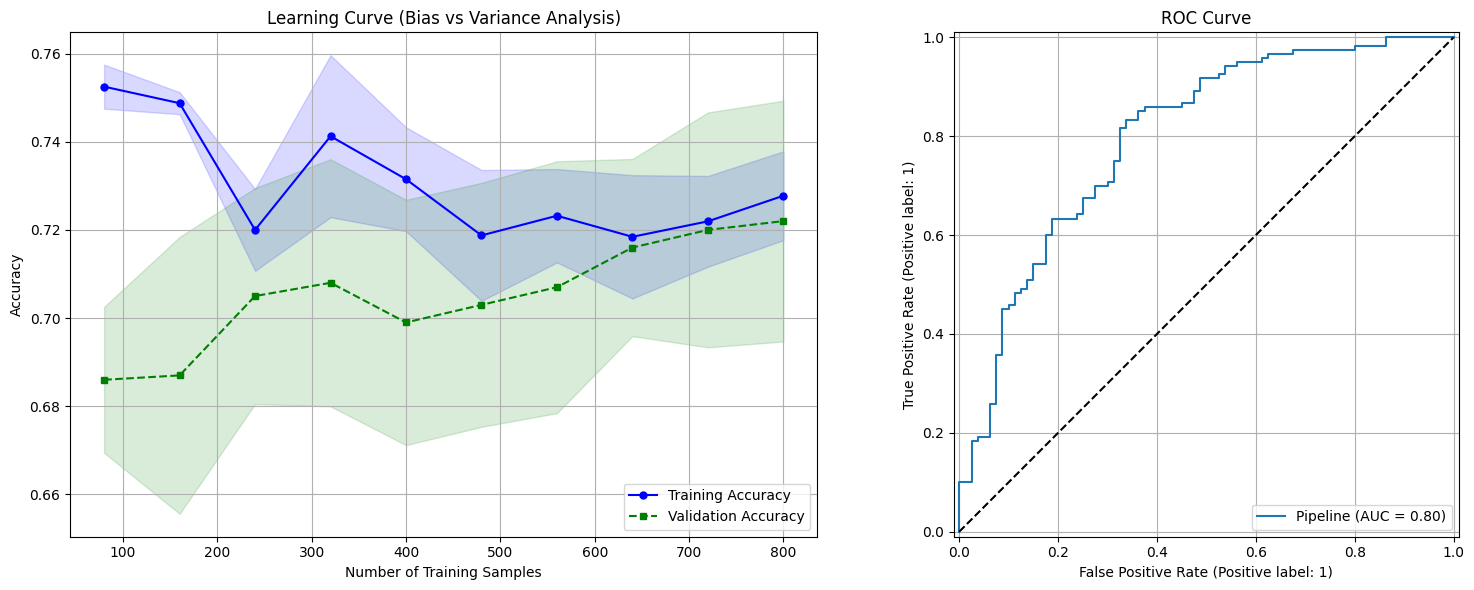

In [53]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import learning_curve
from sklearn.metrics import RocCurveDisplay

# Calculate learning curves to inspect bias (underfitting) and variance (overfitting)
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model_pipeline,
    X=X,
    y=y,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=5,
    n_jobs=-1,
    scoring='accuracy'
)

# Compute mean and standard deviation of training and test scores
train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
test_mean = np.mean(test_scores, axis=1)
test_std = np.std(test_scores, axis=1)

# Plot Bias-Variance Diagnostic (Learning Curves) and ROC Curve side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Learning Curve
axes[0].plot(train_sizes, train_mean, color='blue', marker='o', markersize=5, label='Training Accuracy')
axes[0].fill_between(train_sizes, train_mean + train_std, train_mean - train_std, alpha=0.15, color='blue')
axes[0].plot(train_sizes, test_mean, color='green', linestyle='--', marker='s', markersize=5, label='Validation Accuracy')
axes[0].fill_between(train_sizes, test_mean + test_std, test_mean - test_std, alpha=0.15, color='green')

axes[0].set_title('Learning Curve (Bias vs Variance Analysis)')
axes[0].set_xlabel('Number of Training Samples')
axes[0].set_ylabel('Accuracy')
axes[0].grid(True)
axes[0].legend(loc='lower right')

# Plot 2: ROC Curve
RocCurveDisplay.from_estimator(model_pipeline, X_test, y_test, ax=axes[1])
axes[1].plot([0, 1], [0, 1], 'k--', label='Random Guess')
axes[1].set_title('ROC Curve')
axes[1].grid(True)

plt.tight_layout()
plt.show()

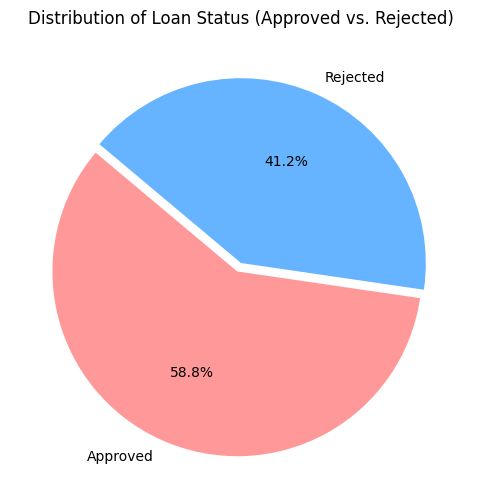

In [54]:
import matplotlib.pyplot as plt

# Count the occurrences of each status
status_counts = df_loans['Loan_Status'].value_counts()

# Plot the pie chart
plt.figure(figsize=(8, 6))
plt.pie(
    status_counts,
    labels=status_counts.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=['#ff9999','#66b3ff'],
    explode=(0.05, 0)
)
plt.title('Distribution of Loan Status (Approved vs. Rejected)')
plt.show()

### Test Your Custom Data
Adjust the form fields on the right and run the cell below to test how the model behaves on custom input values!

In [57]:
import ipywidgets as widgets
from IPython.display import display, HTML
import pandas as pd

# Input widgets with standard styling
style = {'description_width': 'initial'}

name_input = widgets.Text(value='Arun', description='Applicant Name:', style=style)
income_input = widgets.IntText(value=6500, description='Applicant Income ($):', style=style)
co_income_input = widgets.IntText(value=2500, description='Coapplicant Income ($):', style=style)
loan_amt_input = widgets.IntText(value=180000, description='Loan Amount ($):', style=style)
credit_input = widgets.IntSlider(value=720, min=300, max=850, step=10, description='Credit Score:', style=style)
area_input = widgets.Dropdown(options=['Urban', 'Semi-Urban', 'Rural'], value='Semi-Urban', description='Property Area:', style=style)
age_input = widgets.IntSlider(value=30, min=18, max=100, description='Age:', style=style)
dues_input = widgets.Dropdown(options=['Yes', 'No'], value='No', description='Previous Loan Dues:', style=style)
assets_input = widgets.IntText(value=250000, description='Assets ($):', style=style)

submit_btn = widgets.Button(
    description='Submit Details',
    button_style='primary',
    layout=widgets.Layout(width='100%', margin='15px 0px 0px 0px')
)

output_container = widgets.Output()

def on_submit(b):
    with output_container:
        output_container.clear_output()
        try:
            # Load inputs directly
            user_input = pd.DataFrame({
                'Applicant_Income': [float(income_input.value)],
                'Coapplicant_Income': [float(co_income_input.value)],
                'Loan_Amount': [float(loan_amt_input.value)],
                'Credit_Score': [float(credit_input.value)],
                'Property_Area': [str(area_input.value)],
                'Age': [float(age_input.value)],
                'Previous_Loan_Dues': [str(dues_input.value)],
                'Assets': [float(assets_input.value)]
            })

            # Calculate inference
            prediction_id = model_pipeline.predict(user_input)[0]
            prediction_prob = model_pipeline.predict_proba(user_input)[0][1]

            status = "Approved" if prediction_id == 1 else "Rejected"
            color = "#2e7d32" if status == "Approved" else "#c62828"

            # Clean visual presentation inside output container
            display(HTML(f"""
            <div style='padding: 15px; border-radius: 6px; border: 1px solid #ccc; background-color: #fcfcfc; font-family: sans-serif; margin-top: 15px;'>
                <h2 style='margin-top: 0; color: #333;'>Hello, {name_input.value}!</h2>
                <p style='font-size: 1.1em; color: #555;'>Your parameters have been evaluated successfully:</p>
                <hr style='border: none; border-top: 1px solid #eee; margin: 10px 0;'>
                <h3 style='margin: 10px 0;'>Prediction Result: <span style='color: {color}; font-weight: bold;'>{status}</span></h3>
                <p style='margin: 5px 0;'><strong>Approval Probability:</strong> {prediction_prob:.2%}</p>
            </div>
            """))
        except Exception as e:
            print("An error occurred while running the prediction:")
            print(e)

submit_btn.on_click(on_submit)

# Design clean layout using widgets VBox and HBox
form_box = widgets.VBox([
    widgets.HTML("<h2 style='font-family:sans-serif; margin-top:0;'>Interactive Loan Prediction Dashboard</h2>"),
    name_input,
    income_input,
    co_income_input,
    loan_amt_input,
    credit_input,
    area_input,
    age_input,
    dues_input,
    assets_input,
    submit_btn,
    output_container
], layout=widgets.Layout(max_width='500px', padding='20px', border='1px solid #ddd', border_radius='8px'))

display(form_box)
